## Введение в молекулярную динамику ##

В этом блокноте вы будете использовать схему Верле для моделирования динамики одномерного гармонического осциллятора и двухямного потенциала.

То есть просто посмотрим на движение точечной массы в заданном потенциале. Пока без случайных сил и всего такого.

In [16]:
#setup the notebook
#%pylab inline
import numpy as np
import matplotlib.pyplot as plt

In [2]:
newParams = {'figure.figsize'  : (8, 8),   # Figure size
             'figure.dpi'      : 100,      # figure resolution
             'axes.titlesize'  : 18,       # fontsize of title
             'axes.labelsize'  : 14,       # fontsize of axes labels
             'axes.linewidth'  : 1,        # width of the figure box lines
             'lines.linewidth' : 2,        # width of the plotted lines
             'savefig.dpi'     : 200,      # resolution of a figured saved using plt.savefig(filename)
             'ytick.labelsize' : 14,       # fontsize of tick labels on y axis
             'xtick.labelsize' : 14,       # fontsize of tick labels on x axis
             'legend.fontsize' : 14,       # fontsize of labels in legend
             #'legend.title_fontsize' : 12,       # fontsize of labels in legend
             'legend.frameon'  : True,     # activate frame on lengend?
            }
plt.rcParams.update(newParams) # Set new plotting parameters

## Часть 1, задаем потенциал и строим его  ##
Эта функция должна вернуть энергию и силу для 1D-гармонического потенциала. Потенциал имеет вид
$U(x) = \frac{1}{2} k (x - x_0)^2$, а сила $F = -\frac{dU(x)}{dx}$

In [3]:
#this function returns the energy and force on a particle from a harmonic potential
def harmonic_oscillator_energy_force(x,k=1,x0=0):
    #calculate the energy on force on the right hand side of the equal signs
    energy = 0.5*k*(x-x0)**2
    force = -k*(x-x0)
    return energy, force

def plot_energy_force(function, xmin=-3,xmax=3,spacing=0.1,**kwargs):
    x_points = np.arange(xmin,xmax+spacing,spacing)
    energies, forces = function(x_points,**kwargs)
    label = 'U(x)'
    for arg in kwargs:
        label=label+', %s=%s'%(arg,str(kwargs[arg]))
    p = plt.plot(x_points,energies,label=label)
    plt.plot(x_points,forces,label='',color=p[0].get_color(),linestyle='--')
    plt.legend(loc=0)
    plt.show()

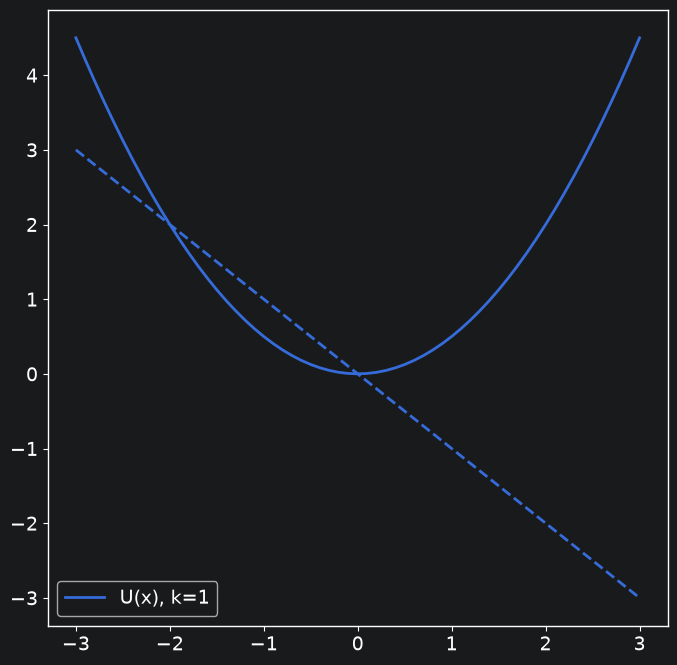

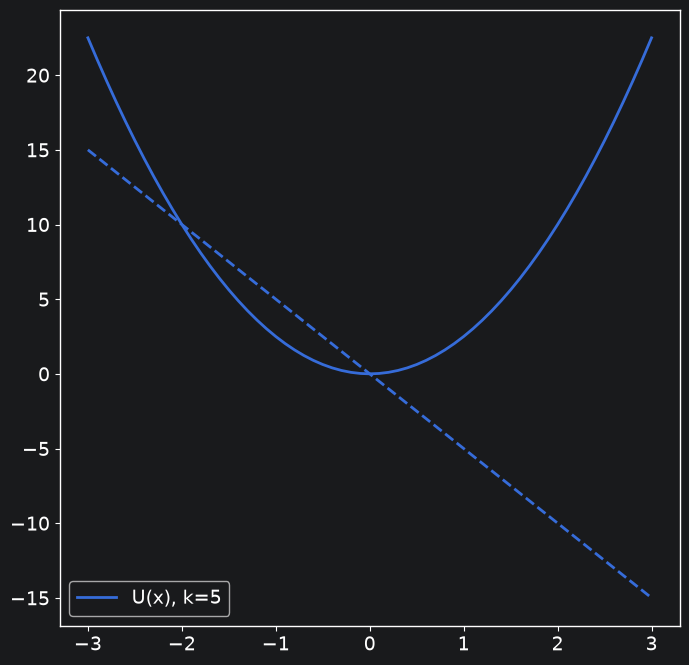

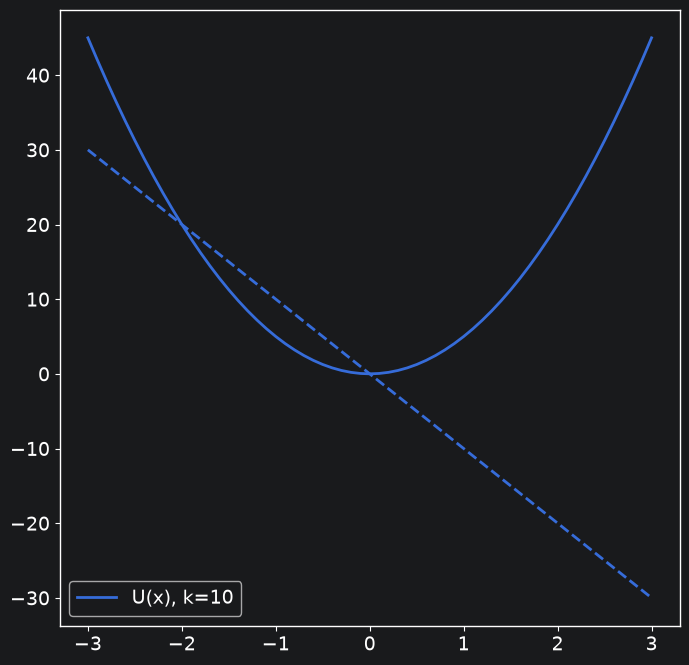

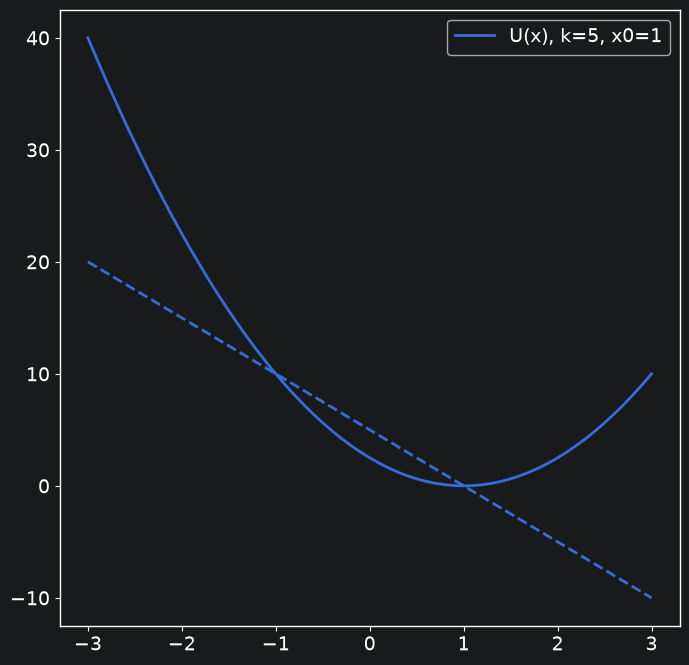

In [4]:
#Мы можем построить энергию (сплошные линии) и силы (пунктирные)
plot_energy_force(harmonic_oscillator_energy_force,k=1)
plot_energy_force(harmonic_oscillator_energy_force,k=5)
plot_energy_force(harmonic_oscillator_energy_force,k=10)
plot_energy_force(harmonic_oscillator_energy_force,k=5,x0=1)

## Часть 2, решение для осциллятора ##
При закоживании нового алгоритма, например молекулярной динамики, всегда полезно начинать с точно решаемой задачи. Мы хотим решить

$F = m a = m \frac{d^2 x}{dt^2}$, где $a$ - вторая производная координаты, а $F = -\frac{dU(x)}{dx}$. Для потенциала гармонического осциллятора, приведенного выше, существует точное решение:

$x(t) = A \cos(\omega t + \phi)$

$v(t) = \frac{d x(t)}{d t} = -A \omega \sin(\omega t + \phi)$

где $\omega=\sqrt{k/m}$

$\phi$ и $A$ задаются начальными условиями. Введем начальную энергию $E$, которая сохраняется в любое время. Нам нужно знать максимальную $x$, где вся энергия является потенциальной энергией, и когда $\cos=1$ (так что $x_{max}=A$). Поэтому $\frac{1}{2} k x_{max}^2 = \frac{1}{2} k A^2 = E$.
Следовательно, $A=\sqrt{2E/k}$. $\phi$ зависит от начальной координаты $x(0) = A \cos(\phi)$.

**Удостоверьтесь, что $\frac{1}{2} m v_{max}^2 = E$.**

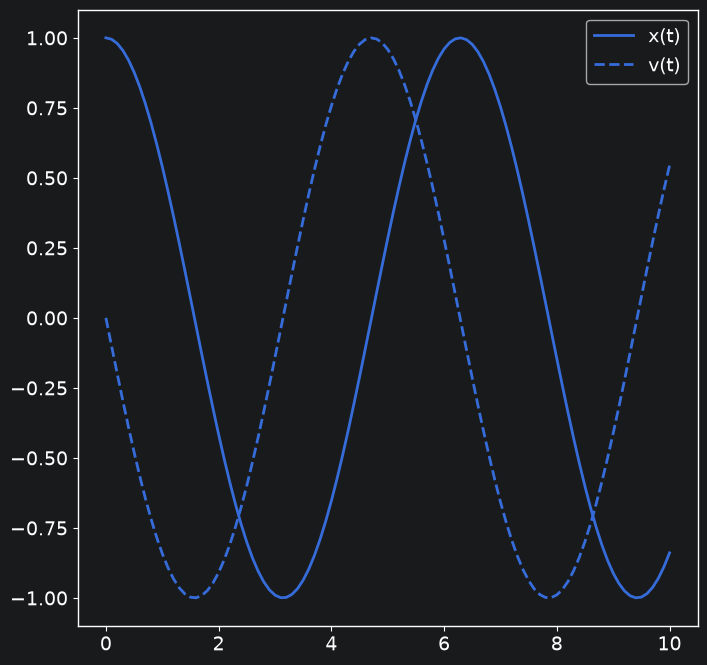

In [5]:
def harmonic_oscillator_position_velocity(t, A=1, omega=1, phi=0):
    position = A*np.cos(omega*t + phi)
    velocity = -A*omega*np.sin(omega*t + phi)
    
    return position, velocity

def plot_harmonic_oscillator(t_max=10,dt=0.1,**kwargs):
    t_points = np.arange(0,t_max+dt,dt)
    position, velocity = harmonic_oscillator_position_velocity(t_points,**kwargs)
    label = 'x(t)'
    for arg in kwargs:
        label=label+', %s=%s'%(arg,str(kwargs[arg]))
    p = plt.plot(t_points,position,label=label)
    plt.plot(t_points,velocity,label='v(t)',color=p[0].get_color(),linestyle='--')
    plt.legend(loc='upper right')
    plt.show()
    
#if it is working, you will get a plot with position as a solid line and velocity as dashed
plot_harmonic_oscillator()

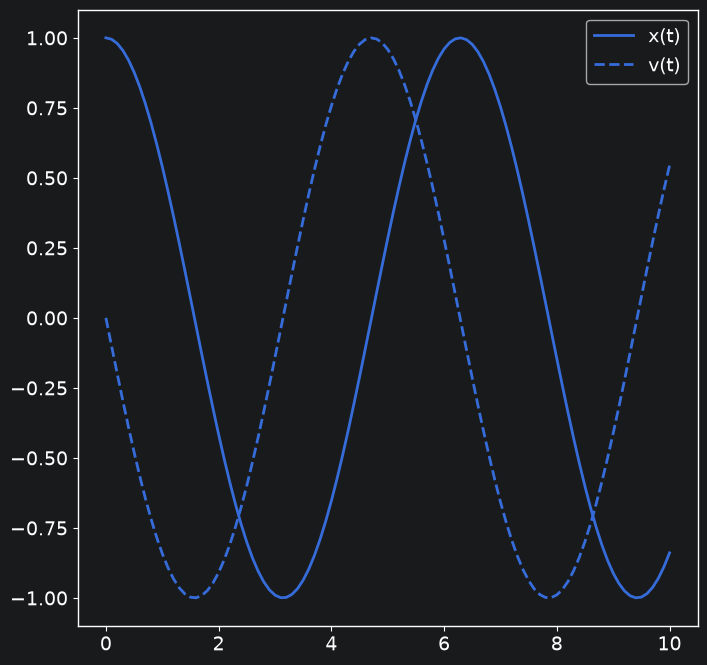

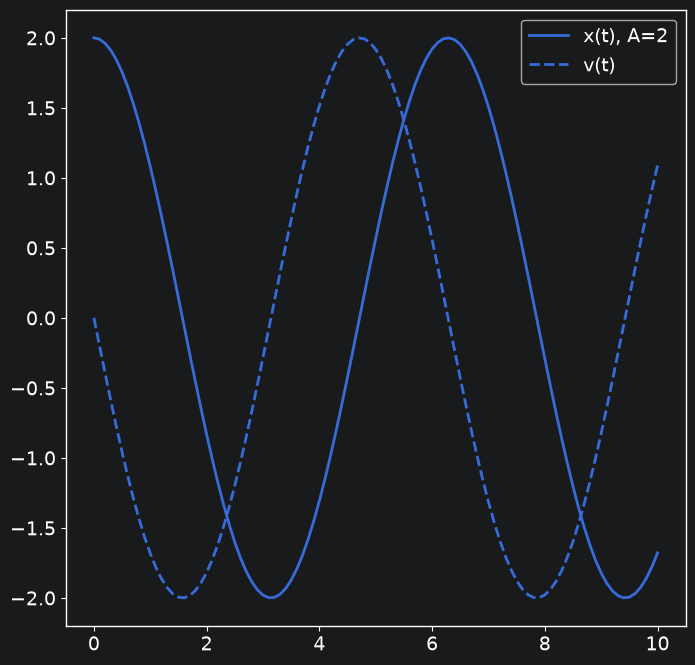

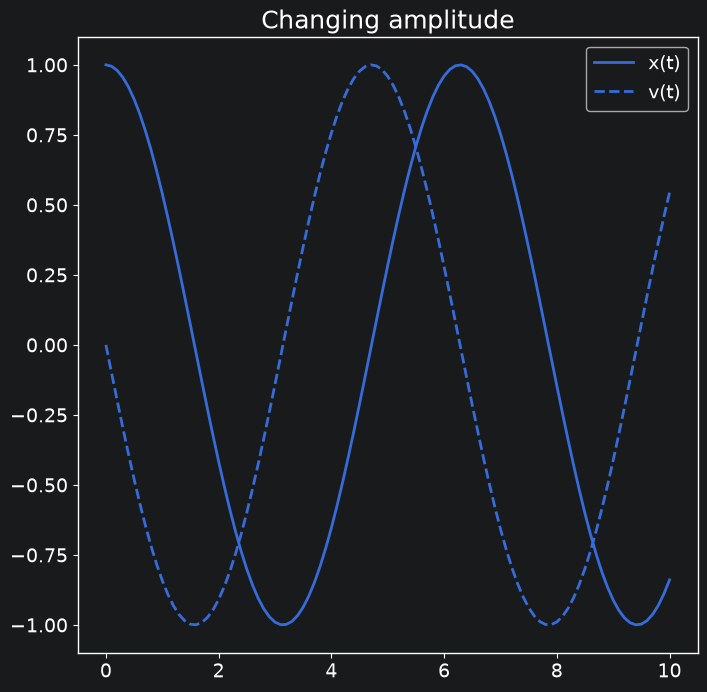

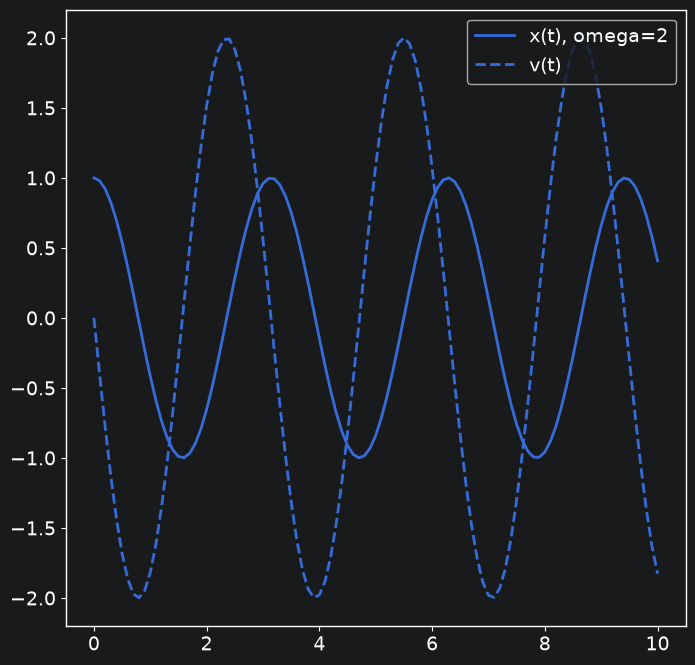

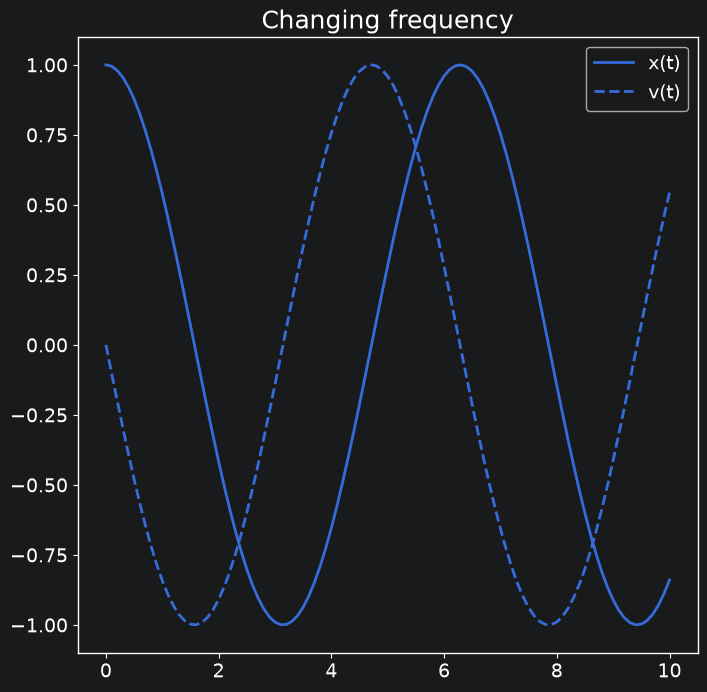

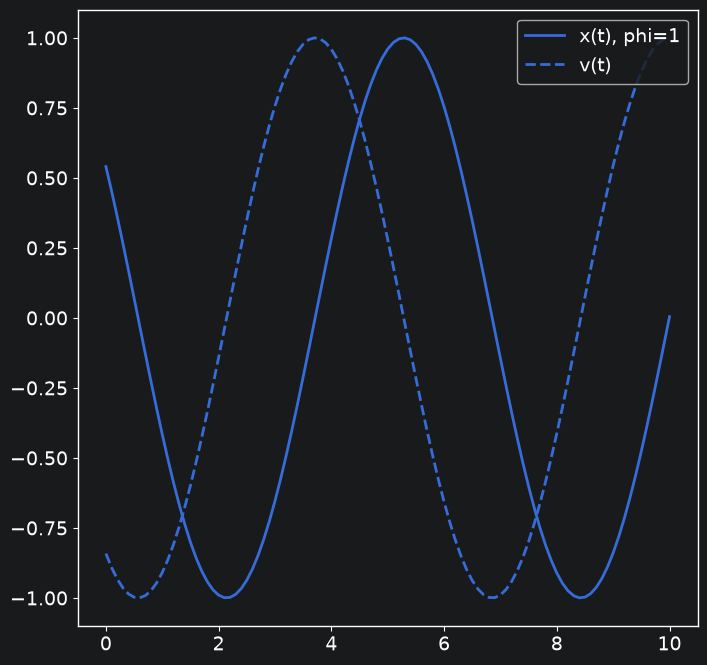

Text(0.5, 1.0, 'Changing phase')

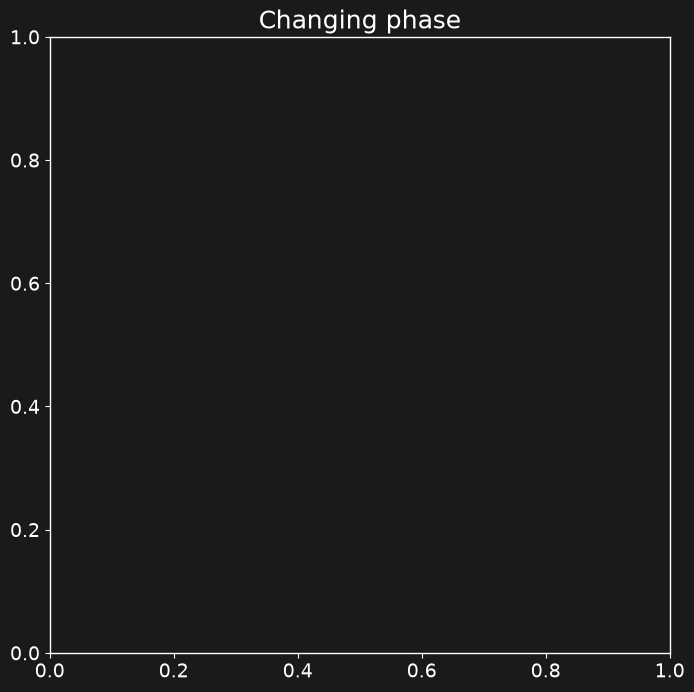

In [6]:
plot_harmonic_oscillator()
plot_harmonic_oscillator(A=2)
plt.title('Changing amplitude')
#lt.figure()
plot_harmonic_oscillator()
plot_harmonic_oscillator(omega=2)
plt.title('Changing frequency')
#plt.figure()
plot_harmonic_oscillator()
plot_harmonic_oscillator(phi=1)
plt.title('Changing phase')

## Часть 3, кодим схему Верле ##

$x(t+dt) = x(t) + dt \cdot v(t) + \frac{dt^2}{2 m} F(t)$

$v(t+dt) = v(t) + \frac{dt}{2m} (F(t+dt) + F(t))$

Обратим внимание, что нужно пересчитывать силы после каждого обновления координаты.

In [7]:
def position_update(x,v,F,dt):
    x_new = x + dt*v + 0.5*F/m*dt**2
    return x_new

def velocity_update(v,F_new,F_old,dt):
    v_new = v + 0.5*dt/m*(F_new+F_old)
    return v_new

#this function will take the initial energy as an input and run velocity verlet dynamics
def velocity_verlet_harmonic_oscillator(potential, max_time, dt, initial_position, initial_velocity,
                                        save_frequency=3, **kwargs ):
    x = initial_position
    v = initial_velocity
    t = 0
    step_number = 0
    positions = []
    velocities = []
    total_energies = []
    save_times = []
    
    while(t<max_time):
        potential_energy, force = potential(x,**kwargs)
        if step_number%save_frequency == 0:
            e_total = .5*v*v + potential_energy

            positions.append(x)
            velocities.append(v)
            total_energies.append(e_total)
            save_times.append(t)
        
        # update the positions
        x = position_update(x,v,force,dt)
        # recompute the energy and force
        potential_energy2, force2 = potential(x,**kwargs)
        # update the velocity
        v = velocity_update(v,force2,force,dt)
                
        t = t+dt
        step_number = step_number + 1
    
    return save_times, positions, velocities, total_energies

### Теперь мы запустим наше MD-моделирование гармонического осциллятора ###
Вы можете выбрать начальную постоянную энергию и жесткость и посмотреть, как выглядят результаты. Если все работает, то энергия должна быть сохранена до намного лучше, чем 1%, а ваши данные моделирования (круги) должны соответствовать точному решению (линии)

In [8]:
initial_energy = 1
my_k = 2
m = 1

my_max_time = 10

#set the initial conditions. this is easiest if you set x=x_max and v=0 based on the input energy E. 
# Otherwise you will have to include a phase factor to show that you got the exact solution

initial_position = 1
initial_velocity = 0

#let's set a good timestep based on dt = tau/100 where tau=2 pi/ omega
my_omega = np.sqrt(my_k)
tau = 2*np.pi/my_omega
my_dt = tau/100.

times, positions, velocities, total_energies = velocity_verlet_harmonic_oscillator(
    harmonic_oscillator_energy_force, my_max_time, my_dt, initial_position, initial_velocity,k=my_k)

# What is the A value prefactor for the harmonic oscillator? See equations above
my_A = np.sqrt(initial_energy*2/my_k)
# Максимальная скорость v_max = A * omega; m*v_max**2/2 = E.
print('Проверка энергии:', 0.5 * m * (my_A * my_omega)**2)

Проверка энергии: 1.0000000000000002


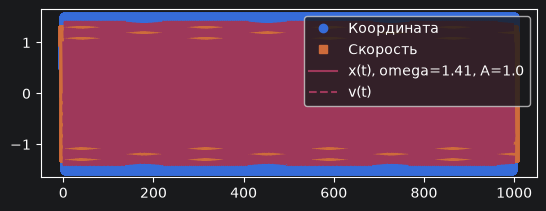

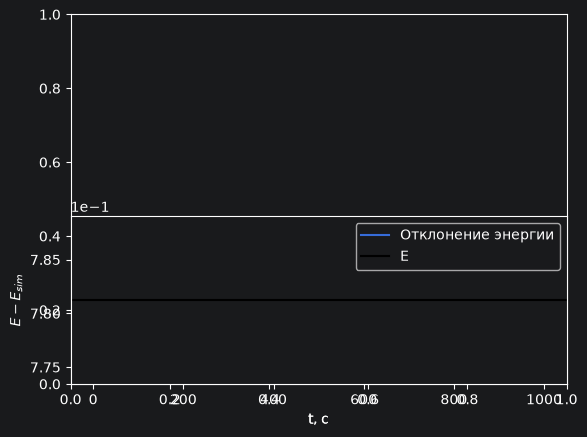

In [21]:
En = [ initial_energy - te for te in total_energies ]
plt.subplot(211)
plt.plot(times,positions,marker='o',label="Координата",linestyle='')
plt.plot(times,velocities,marker='s',label="Скорость",linestyle='')
plt.legend(loc='upper center')
plot_harmonic_oscillator(t_max=my_max_time,omega=round(my_omega,2), A=my_A)
plt.xlabel('t, c')


plt.subplot(212)
plt.plot(times,En,label="Отклонение энергии")
plt.axhline(initial_energy,color='black',label='E')
plt.ylim(0.99*initial_energy,1.01*initial_energy)
plt.xlabel('t, c')
plt.ylabel(r"$E-E_{sim}$")
plt.ticklabel_format(axis='y', style='scientific', scilimits=(0, 0))
plt.legend()
plt.savefig('fig1.png')
plt.show()

### Histogram Position and Velocity ###
Какова вероятность увидеть конкретную координату или скорость? 
Разобраться помогут гистограммы

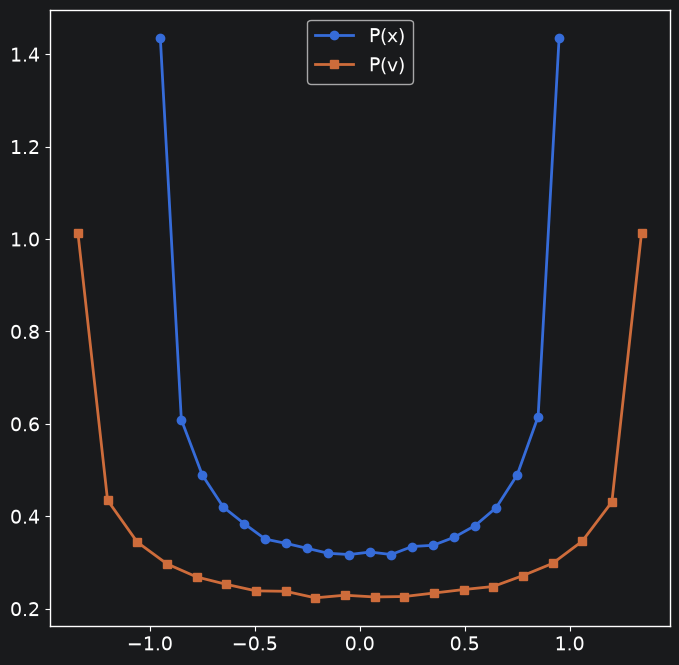

In [10]:
def bin_centers(bin_edges):
    return (bin_edges[1:]+bin_edges[:-1])/2.

#to get a good histogram, we need to run a lot longer than before
my_max_time = 1000

times, positions, velocities, total_energies = velocity_verlet_harmonic_oscillator(
    harmonic_oscillator_energy_force, my_max_time, my_dt, initial_position, initial_velocity, k=my_k)

dist_hist, dist_bin_edges = np.histogram(positions,bins=20,density=True)
vel_hist, vel_bin_edges = np.histogram(velocities,bins=20,density=True)


plt.plot(bin_centers(dist_bin_edges), dist_hist,marker='o',label='P(x)')
plt.plot(bin_centers(vel_bin_edges), vel_hist,marker='s',label='P(v)')
plt.legend(loc='upper center')
plt.savefig('fig2.png')
plt.show()

## Часть 4, строим двухямный потенциал ##
Для гармонического осциллятора мы знали точное решение. Давайте сделаем еще одну подобную проблему для практики.

Рассмотрим еще один полезный потенциал:

$U(x) = \frac{k}{4} (x-a)^2 (x+a)^2$

Этот потенциал имеет минимум при $ x = a $ и $ x = -a $. Он также имеет барьер в $ x = 0 $. 

**Какова высота этого барьера?**

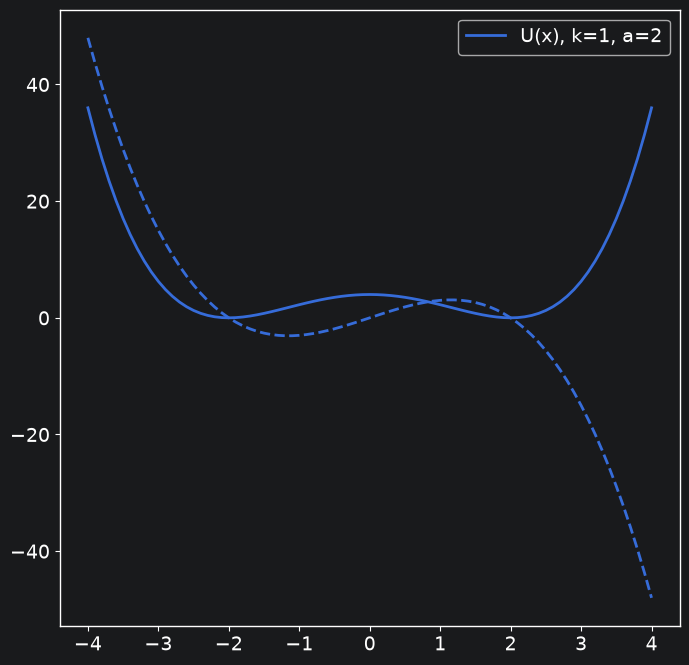

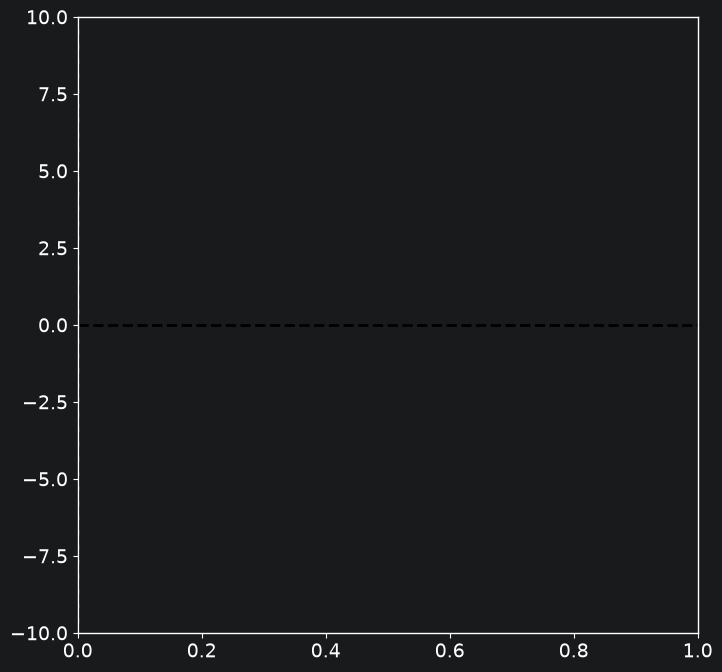

Высота барьера: 4.0


In [11]:
#this function returns the energy and force on a particle from a double well
def double_well_energy_force(x,k,a):
    #calculate the energy on force on the right hand side of the equal signs
    energy = 0.25*k*(x**2-a**2)**2
    force = 0.5*k*( (x-a)*(x+a)**2 + (x+a)*(x-a)**2 )
    return energy, -force

#plt.figure(figsize=(4, 2))
plot_energy_force(double_well_energy_force, xmin=-4,xmax=+4, k=1, a=2)
plt.axhline(0,linestyle='--',color='black')
plt.axvline(0,linestyle='--',color='black')
plt.ylim(-10,10)
plt.show()
# Высота барьера относительно минимума: U(0) = k*a**4/4.
print('Высота барьера:', 1 * 2**4 / 4)

Запускаем динамику:

In [12]:
# make up an initial position and velocity
my_k = 2
my_a = 1
my_initial_position = 0.5
my_initial_velocity = 1.0

my_dt = 0.001
my_max_time = 10

times, positions, velocities, total_energies = velocity_verlet_harmonic_oscillator(
    double_well_energy_force,my_max_time, 
    my_dt,my_initial_position, my_initial_velocity,k=my_k, a=my_a)

In [13]:
len(times)

3334

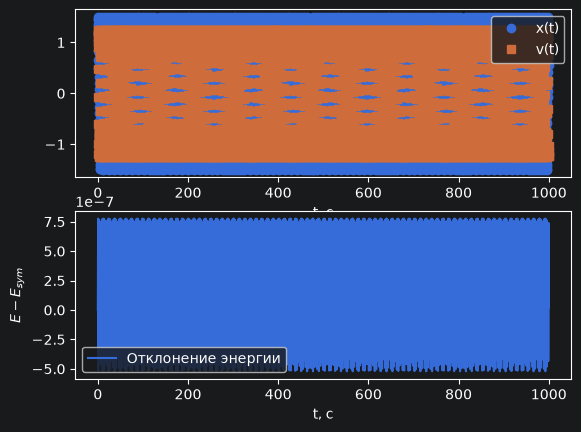

In [22]:
n = 50
plt.subplot(211)
plt.plot(times[::n],positions[::n],marker='o',label='x(t)',linestyle='')
plt.plot(times[::n],velocities[::n],marker='s',label='v(t)',linestyle='')

plt.xlabel('t, c')
plt.legend(loc='upper right')

plt.subplot(212)
initial_energy = total_energies[0]
En = [ initial_energy - te for te in total_energies[::n] ]
plt.plot(times[::n], En, label='Отклонение энергии')
#plt.axhline(initial_energy,color='black',label='Exact')
#plt.ylim(0.999*initial_energy,1.001*initial_energy)
plt.ticklabel_format(axis='y', style='scientific', scilimits=(0, 0))
plt.xlabel('t, c')
plt.ylabel(r"$E-E_{sym}$")
plt.legend()
plt.savefig('fig3.png')
plt.show()

И гистограммы:

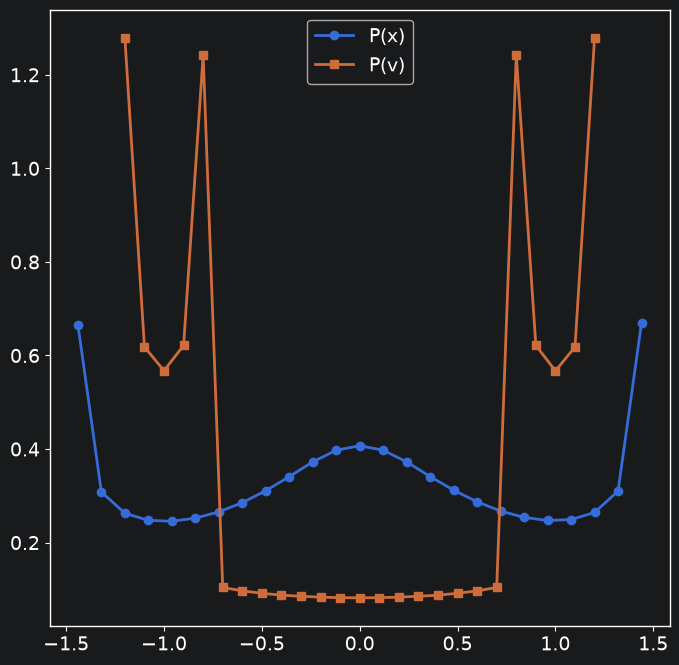

In [15]:
#to get a good histogram, we need to run a lot longer than before
my_max_time = 1000

times, positions, velocities, total_energies = velocity_verlet_harmonic_oscillator(
    double_well_energy_force, my_max_time, my_dt, 
    my_initial_position, my_initial_velocity, k=my_k, a=my_a)

dist_hist, dist_bin_edges = np.histogram(positions,bins=25,density=True)
vel_hist, vel_bin_edges = np.histogram(velocities,bins=25,density=True)


plt.plot(bin_centers(dist_bin_edges), dist_hist,marker='o',label='P(x)')
plt.plot(bin_centers(vel_bin_edges), vel_hist,marker='s',label='P(v)')
plt.legend(loc='upper center')
plt.savefig('fig4.png')
plt.show()